In [1]:
#import some basic classes
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.util as cutil
import matplotlib.pyplot as plt
#import statsmodels.api as sm
from tqdm import tqdm
from scipy import stats
#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

In [2]:
def check_zg_pIB(ds,zg="",pIB=""):
  try:
    zg = ds[zg]
    pIB = ds[pIB]
    string = "data read successfully"
  except:
    string = "Error code 2: zg variable and pIB were not found. " +\
    "Hint: use read_main() to load data with right attributes."
    print(ds)
    print(string)
    return 2

  #____CHECK GEOP HEIGHT____
  #ERA5 dataset uses geopotential, not height
  try:
    if zg.values[0,0,0,0] > 10000:
      zg = zg/9.80665
  except:
    if zg.values[0,0,0] > 10000:
      zg = zg/9.80665
      
  #creating arrays
  try:
    dat1 = zg.values[:,0,:,:]
    dat2 = pIB.values[:,0,:,:]
  except:
    dat1 = zg.values
    dat2 = pIB.values
  #preparing horizontal positions
  lats = ds.lat.values
  lons = ds.lon.values

  #adding an element to longitude direction as needed by cartopy stereographic transforms
  if lons[len(lons)-1] != lons[0]:
    lons = np.append(lons,180-10**(-6))#slightly different for avoiding contour bug
    dat1 = cutil.add_cyclic_point(dat1)
    dat2 = cutil.add_cyclic_point(dat2)
  return lons,lats,dat1,dat2


In [3]:
def PlotLabel(ds,
              output,
              label,
              shuffle = False,
              pIB_tracked="pIB_tracked", #name of IB matrix variable, may vary from file to file
              zg="zg", #name of zg500 matrix, may vary from file to file
              mapcrs = ccrs.PlateCarree(),
              datacrs = ccrs.PlateCarree(),
              extent =[-180,180,0,90]):
  lons,lats,dat1,dat2 = check_zg_pIB(ds,"zg",pIB_tracked)
  #selecting data from the desired days
  #create a list of indexes
  for t in range(len(ds["time"].values)):
    if label in dat2[t,:,:]:
      index1 = t
      break
  time = ds["time"].values
  starting_day = str(time[index1-3])
  index1 = index1-3
  if shuffle == True:
    index1 = index1 + 15
  index2 = index1 + 15
  dat1 = dat1[index1:index2,:,:]
  dat2 = dat2[index1:index2,:,:]
  print(index1,index2)
  bl = dat2!=label
  dat2[bl] = 0
  #multiple plots for having both contours and flags over different days
  min = np.amin(dat2) #store min and max for following calculation
  max = np.amax(dat2)
  dat2 = np.ma.masked_equal(dat2,0) #mask array1 when ==0
  dat2 = np.where(dat2==label,1,0)
  for i in range(0,15):
    ax = plt.subplot(5,3,i+1, projection=mapcrs, aspect = 1.0)
    ax.set_extent(extent, datacrs)
    ax.coastlines(alpha=0.6)
    ax.set_aspect(2)
    #define ranges
    cs_range = np.arange(5100,6000,80) #usually it works
    N=1
    #plot contour
    #dat2 is normalized in 0,1
    cs_b = ax.contourf(lons, lats,dat1[i,:,:], cs_range,cmap='jet' ,extend='both',transform=datacrs)#sec>    plt.clabel(cs_b, colors ="black", fontsize = 5, inline ="false")
    cb = ax.contour(lons,lats,dat2[i,:,:],colors = 'black', levels = [0.5,1.5],linewidths = 2 ,transform=datacrs)#blocking plot
    # create the colorbar
    cb.set_label('blocking event label')
    # Make some nice titles for the plot
    plt.title(starting_day[0:8] + starting_day[8:10] + ' + ' + str(i) + ' days',fontsize = 12, loc='left')
  plt.suptitle('Event #' + str(label))
  #Export image
  try:
    plt.savefig(output,bbox_inches='tight',dpi=250)
    return 0
  except:
    print("Error code 1: no output file was given or something went wrong with matplotlib")
    return 1

In [4]:
%cd /emmy-noether/home/mf671/DATA/ERA5/gr_tracking
#!cdo selmon,6,7,8 ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_jja_1940-2023.nc
!ls

/emmy-noether/home/mf671/DATA/ERA5/gr_tracking
dictionaries
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_tyrlis_EW_mod.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_tyrlis_EW.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_tyrlis.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_tyrlis_YMONMEAN.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_YMONMEAN.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1990-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_djf_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023_tyrlis.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023_tyrlis_EW_mod.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023_tyrlis_EW.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1

In [5]:
ds = xr.open_dataset('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1960-1963.nc')
output = '/emmy-noether/home/mf671/github/greenland_blocking/PLOTS/tracking_15days.png'
ds['time'][0]

<xarray.DataArray 'time' ()> Size: 8B
array('1960-01-01T06:00:00.000000000', dtype='datetime64[ns]')
Coordinates:
    time     datetime64[ns] 8B 1960-01-01T06:00:00

121 136


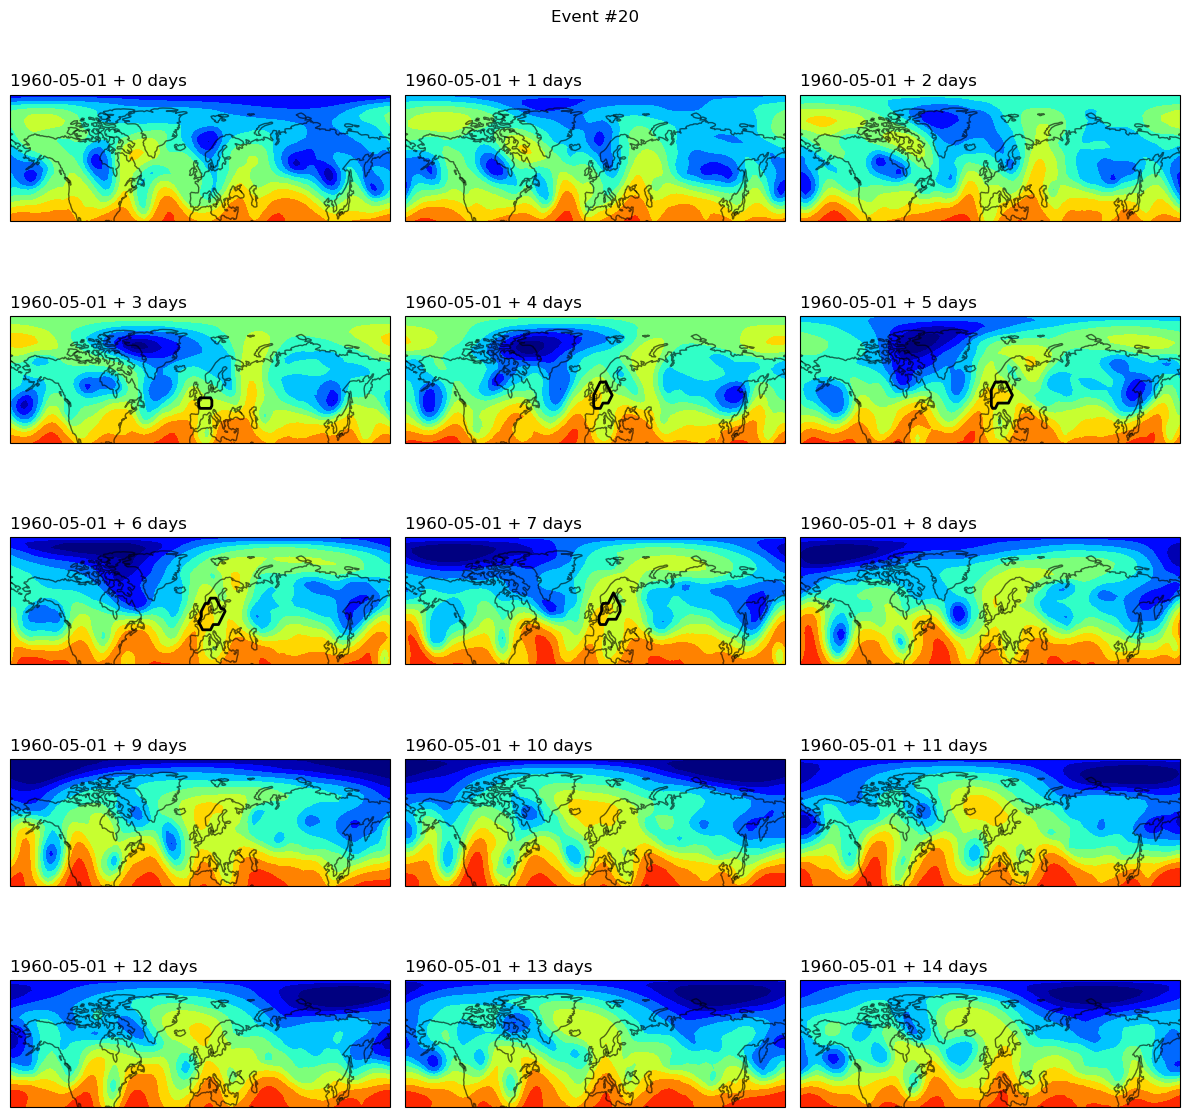

In [9]:
plt.figure(figsize=(12,12))
PlotLabel(ds,
             output,
             label=20,
             pIB_tracked="DAV_tracked", #name of IB matrix variable, may vary from file to file
             shuffle = False,
             zg="zg", #name of zg500 matrix, may vary from file to file
             mapcrs = ccrs.PlateCarree(),
             datacrs = ccrs.PlateCarree(),
             extent =[-180,+180,30,90])
plt.tight_layout()